# **STAT 650 Project**

###**Tanaya Jadhav**

###**UIN - 635009193**

###**Department of Information and Operations Management**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay)

##**5. DATA**
###**1. Loading the dataset**

In [ ]:
file_id = "1iU3NbpJYid8uskCfF1Iu001J-rPHWynE"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

# Load the dataset
df = pd.read_csv(url)

# Basic info
print("Shape:", df.shape)
print("\nColumn names and dtypes:")
print(df.dtypes)

Shape: (9168, 21)

Column names and dtypes:
id                          int64
brand                      object
category                   object
name                       object
size                       object
rating                    float64
number_of_reviews           int64
love                        int64
price                     float64
value_price               float64
URL                        object
MarketingFlags               bool
MarketingFlags_content     object
options                    object
details                    object
how_to_use                 object
ingredients                object
online_only                 int64
exclusive                   int64
limited_edition             int64
limited_time_offer          int64
dtype: object


In [ ]:
print("\nFirst 3 rows:")
df.head(3)


First 3 rows:


,id,brand,category,name,size,rating,number_of_reviews,love,price,value_price,...,MarketingFlags,MarketingFlags_content,options,details,how_to_use,ingredients,online_only,exclusive,limited_edition,limited_time_offer
0,2218774,Acqua Di Parma,Fragrance,Blu Mediterraneo MINIATURE Set,5 x 0.16oz/5mL,4.0,4,3002,66.0,75.0,...,True,online only,no options,This enchanting set comes in a specially handc...,Suggested Usage:-Fragrance is intensified by t...,Arancia di Capri Eau de Toilette: Alcohol Dena...,1,0,0,0
1,2044816,Acqua Di Parma,Cologne,Colonia,0.7 oz/ 20 mL,4.5,76,2700,66.0,66.0,...,True,online only,- 0.7 oz/ 20 mL Spray - 1.7 oz/ 50 mL Eau d...,An elegant timeless scent filled with a fresh-...,no instructions,unknown,1,0,0,0
2,1417567,Acqua Di Parma,Perfume,Arancia di Capri,5 oz/ 148 mL,4.5,26,2600,180.0,180.0,...,True,online only,- 1oz/30mL Eau de Toilette - 2.5 oz/ 74 mL E...,Fragrance Family: Fresh Scent Type: Fresh Citr...,no instructions,Alcohol Denat.- Water- Fragrance- Limonene- Li...,1,0,0,0


###**Missing Values & Data Review**

In [ ]:
# Missing values
print("Missing values per column:")
print(df.isnull().sum())

print("\nMissing value percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

# Check rating = 0 (unrated products)
print("\nProducts with rating == 0:", (df['rating'] == 0).sum())

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

# Unique values in categorical columns
for col in ['brand', 'category', 'online_only', 'exclusive', 'limited_edition', 'limited_time_offer']:
    print(f"\n{col} - unique values: {df[col].nunique()}")
    if df[col].nunique() <= 10:
        print(df[col].value_counts())

Missing values per column:
id                        0
brand                     0
category                  0
name                      0
size                      0
rating                    0
number_of_reviews         0
love                      0
price                     0
value_price               0
URL                       0
MarketingFlags            0
MarketingFlags_content    0
options                   0
details                   0
how_to_use                0
ingredients               0
online_only               0
exclusive                 0
limited_edition           0
limited_time_offer        0
dtype: int64

Missing value percentage:
id                        0.0
brand                     0.0
category                  0.0
name                      0.0
size                      0.0
rating                    0.0
number_of_reviews         0.0
love                      0.0
price                     0.0
value_price               0.0
URL                       0.0
MarketingFlags 

###**Data Cleaning**

In [ ]:
# Step 1: Remove unrated products (rating == 0)
df_clean = df[df['rating'] != 0].copy()
print("Rows after removing unrated products:", len(df_clean))

# Step 2: Drop non-analytical columns
cols_to_drop = ['URL', 'MarketingFlags', 'MarketingFlags_content',
                'options', 'details', 'how_to_use', 'ingredients', 'size', 'name']
df_clean = df_clean.drop(columns=cols_to_drop)
print("Columns after dropping non-analytical columns:", df_clean.shape)

# Step 3: Drop rows with missing price or value_price
df_clean = df_clean.dropna(subset=['price', 'value_price', 'rating'])
print("Rows after dropping missing price/rating:", len(df_clean))

# Final shape
print("\nFinal cleaned dataset shape:", df_clean.shape)
print(df_clean.dtypes)

Rows after removing unrated products: 8770
Columns after dropping non-analytical columns: (8770, 12)
Rows after dropping missing price/rating: 8770

Final cleaned dataset shape: (8770, 12)
id                      int64
brand                  object
category               object
rating                float64
number_of_reviews       int64
love                    int64
price                 float64
value_price           float64
online_only             int64
exclusive               int64
limited_edition         int64
limited_time_offer      int64
dtype: object


In [ ]:
df_clean.head()

,id,brand,category,rating,number_of_reviews,love,price,value_price,online_only,exclusive,limited_edition,limited_time_offer
0,2218774,Acqua Di Parma,Fragrance,4.0,4,3002,66.0,75.0,1,0,0,0
1,2044816,Acqua Di Parma,Cologne,4.5,76,2700,66.0,66.0,1,0,0,0
2,1417567,Acqua Di Parma,Perfume,4.5,26,2600,180.0,180.0,1,0,0,0
3,1417617,Acqua Di Parma,Perfume,4.5,23,2900,120.0,120.0,1,0,0,0
4,2218766,Acqua Di Parma,Fragrance,3.5,2,943,72.0,80.0,1,0,0,0


###**Summary Statistics**

In [ ]:
# Numeric variables summary
print("Summary statistics for numeric variables:")
print(df_clean[['price', 'value_price', 'rating', 'number_of_reviews', 'love']].describe().round(2))

# Categorical variable distributions
print("\nTop 10 brands by product count:")
print(df_clean['brand'].value_counts().head(10))

print("\nTop 10 categories by product count:")
print(df_clean['category'].value_counts().head(10))

print("\nBinary variable counts:")
for col in ['online_only', 'exclusive', 'limited_edition', 'limited_time_offer']:
    print(f"{col}:\n{df_clean[col].value_counts()}\n")

Summary statistics for numeric variables:
         price  value_price   rating  number_of_reviews        love
count  8770.00      8770.00  8770.00            8770.00     8770.00
mean     49.82        51.33     4.17             294.88    16984.27
std      46.88        48.94     0.55             908.55    43425.24
min       2.00         2.00     1.00               1.00        0.00
25%      24.00        25.00     4.00              13.00     1900.00
50%      35.00        35.00     4.50              53.00     5200.00
75%      58.00        60.00     4.50             224.00    14600.00
max     549.00       549.00     5.00           19000.00  1300000.00

Top 10 brands by product count:
brand
SEPHORA COLLECTION    465
CLINIQUE              219
tarte                 169
TOM FORD              154
Fresh                 137
Dior                  137
Kiehl's Since 1851    124
Lancôme               114
Bumble and bumble     101
MAKE UP FOR EVER       98
Name: count, dtype: int64

Top 10 categories by

###**Visualizations**

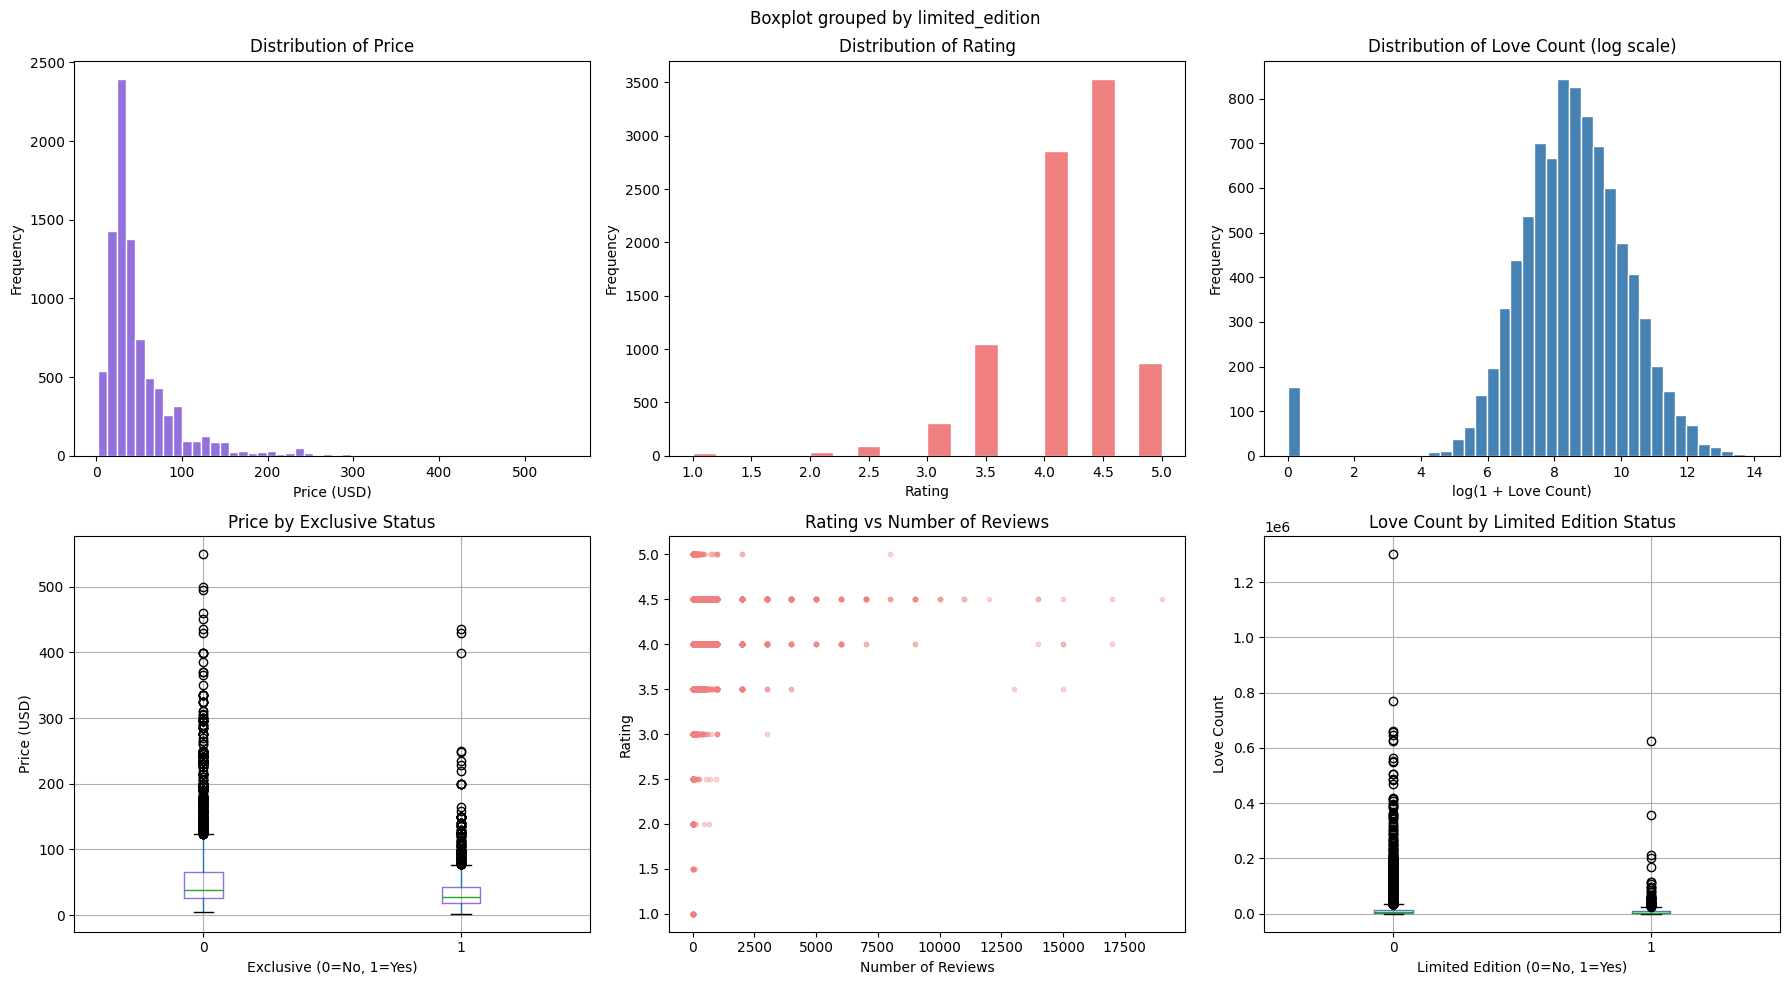

Plot saved.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Sephora Dataset - EDA Visualizations", fontsize=16)

# 1. Price distribution
axes[0, 0].hist(df_clean['price'], bins=50, color='mediumpurple', edgecolor='white')
axes[0, 0].set_title("Distribution of Price")
axes[0, 0].set_xlabel("Price (USD)")
axes[0, 0].set_ylabel("Frequency")

# 2. Rating distribution
axes[0, 1].hist(df_clean['rating'], bins=20, color='lightcoral', edgecolor='white')
axes[0, 1].set_title("Distribution of Rating")
axes[0, 1].set_xlabel("Rating")
axes[0, 1].set_ylabel("Frequency")

# 3. Love count distribution (log scale)
axes[0, 2].hist(np.log1p(df_clean['love']), bins=40, color='steelblue', edgecolor='white')
axes[0, 2].set_title("Distribution of Love Count (log scale)")
axes[0, 2].set_xlabel("log(1 + Love Count)")
axes[0, 2].set_ylabel("Frequency")

# 4. Price by exclusive status
df_clean.boxplot(column='price', by='exclusive', ax=axes[1, 0],
                 boxprops=dict(color='mediumpurple'))
axes[1, 0].set_title("Price by Exclusive Status")
axes[1, 0].set_xlabel("Exclusive (0=No, 1=Yes)")
axes[1, 0].set_ylabel("Price (USD)")
plt.sca(axes[1, 0])
plt.title("Price by Exclusive Status")

# 5. Rating vs Number of Reviews (scatter)
axes[1, 1].scatter(df_clean['number_of_reviews'], df_clean['rating'],
                   alpha=0.3, color='lightcoral', s=10)
axes[1, 1].set_title("Rating vs Number of Reviews")
axes[1, 1].set_xlabel("Number of Reviews")
axes[1, 1].set_ylabel("Rating")

# 6. Love count by limited_edition
df_clean.boxplot(column='love', by='limited_edition', ax=axes[1, 2],
                 boxprops=dict(color='steelblue'))
axes[1, 2].set_title("Love Count by Limited Edition Status")
axes[1, 2].set_xlabel("Limited Edition (0=No, 1=Yes)")
axes[1, 2].set_ylabel("Love Count")
plt.sca(axes[1, 2])
plt.title("Love Count by Limited Edition Status")

plt.tight_layout()
plt.savefig("eda_visualizations.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved.")

###**Response Variable Association Plots (RQ-specific)**

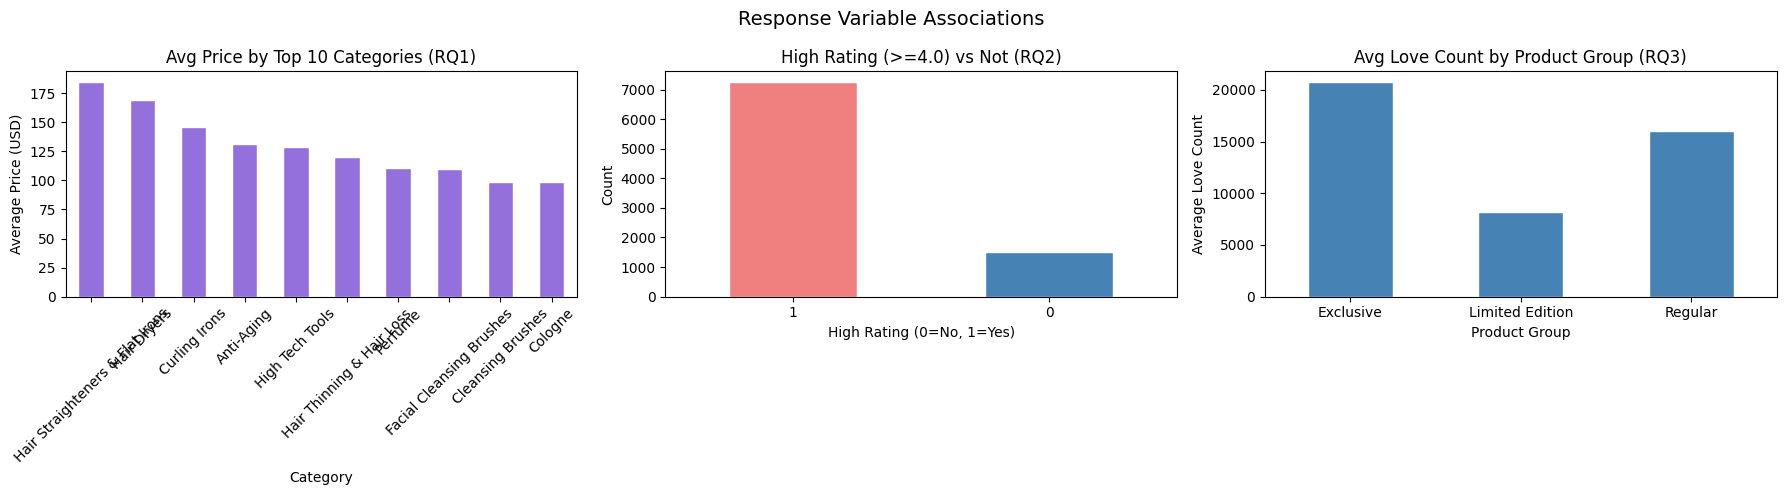

Plot saved.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Response Variable Associations", fontsize=14)

# RQ1: Average price by top 10 categories
top_cats = df_clean.groupby('category')['price'].mean().sort_values(ascending=False).head(10)
top_cats.plot(kind='bar', ax=axes[0], color='mediumpurple', edgecolor='white')
axes[0].set_title("Avg Price by Top 10 Categories (RQ1)")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Average Price (USD)")
axes[0].tick_params(axis='x', rotation=45)

# RQ2: Create binary high_rating and plot counts
df_clean['high_rating'] = (df_clean['rating'] >= 4.0).astype(int)
df_clean['high_rating'].value_counts().plot(kind='bar', ax=axes[1],
                                             color=['lightcoral', 'steelblue'],
                                             edgecolor='white')
axes[1].set_title("High Rating (>=4.0) vs Not (RQ2)")
axes[1].set_xlabel("High Rating (0=No, 1=Yes)")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=0)

# RQ3: Average love count by exclusive + limited_edition groups
df_clean['group'] = df_clean.apply(
    lambda x: 'Exclusive' if x['exclusive'] == 1
    else ('Limited Edition' if x['limited_edition'] == 1 else 'Regular'), axis=1)
df_clean.groupby('group')['love'].mean().plot(kind='bar', ax=axes[2],
                                               color='steelblue', edgecolor='white')
axes[2].set_title("Avg Love Count by Product Group (RQ3)")
axes[2].set_xlabel("Product Group")
axes[2].set_ylabel("Average Love Count")
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig("rq_associations.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved.")

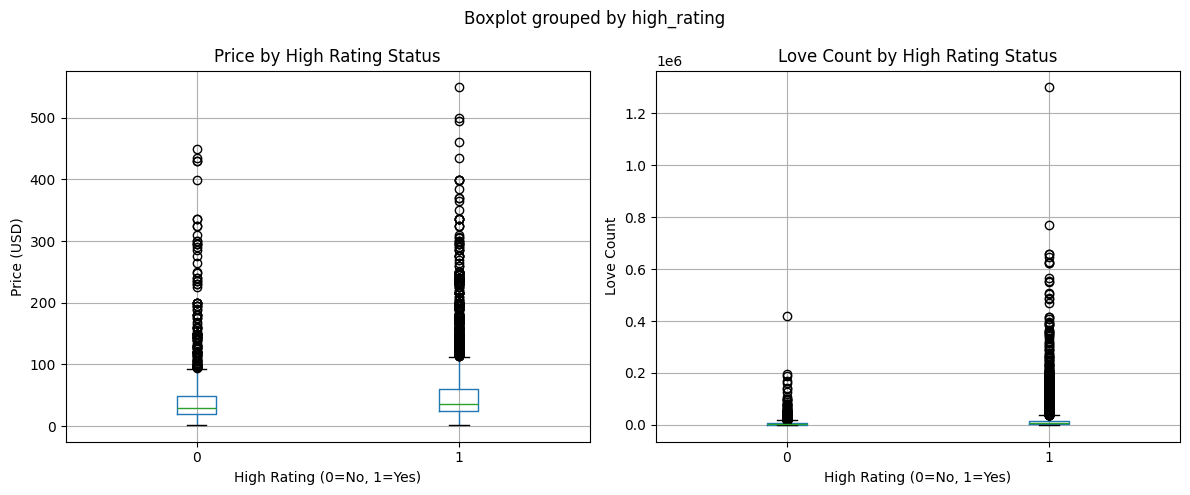

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("RQ2: Predictors vs High Rating", fontsize=13)

# Price by high rating
df_clean.boxplot(column='price', by='high_rating', ax=axes[0])
axes[0].set_title("Price by High Rating Status")
axes[0].set_xlabel("High Rating (0=No, 1=Yes)")
axes[0].set_ylabel("Price (USD)")
plt.sca(axes[0])
plt.title("Price by High Rating Status")

# Love count by high rating
df_clean.boxplot(column='love', by='high_rating', ax=axes[1])
axes[1].set_title("Love Count by High Rating Status")
axes[1].set_xlabel("High Rating (0=No, 1=Yes)")
axes[1].set_ylabel("Love Count")
plt.sca(axes[1])
plt.title("Love Count by High Rating Status")

plt.tight_layout()
plt.savefig("rq2_associations.png", dpi=150, bbox_inches='tight')
plt.show()

##**6. METHODOLOGY**
###**Question - 1**
####**Data Prep for MLR**

In [ ]:
top10_cats = df_clean['category'].value_counts().head(10).index.tolist()
df_clean['category_grouped'] = df_clean['category'].apply(
    lambda x: x if x in top10_cats else 'Other'
)

df_rq1 = pd.get_dummies(df_clean[['price', 'category_grouped', 'online_only',
                                    'exclusive', 'limited_edition']],
                          columns=['category_grouped'], drop_first=True)

# Fix: convert all bool columns to int
df_rq1 = df_rq1.astype({col: int for col in df_rq1.select_dtypes(include='bool').columns})

print("RQ1 dataset shape:", df_rq1.shape)
print(df_rq1.dtypes)

RQ1 dataset shape: (8770, 14)
price                                         float64
online_only                                     int64
exclusive                                       int64
limited_edition                                 int64
category_grouped_Eye Palettes                   int64
category_grouped_Face Masks                     int64
category_grouped_Face Serums                    int64
category_grouped_Face Wash & Cleansers          int64
category_grouped_Hair Styling Products          int64
category_grouped_Moisturizers                   int64
category_grouped_Other                          int64
category_grouped_Perfume                        int64
category_grouped_Rollerballs & Travel Size      int64
category_grouped_Value & Gift Sets              int64
dtype: object


In [ ]:
df_rq1.columns.tolist()

['price',
 'online_only',
 'exclusive',
 'limited_edition',
 'category_grouped_Eye Palettes',
 'category_grouped_Face Masks',
 'category_grouped_Face Serums',
 'category_grouped_Face Wash & Cleansers',
 'category_grouped_Hair Styling Products',
 'category_grouped_Moisturizers',
 'category_grouped_Other',
 'category_grouped_Perfume',
 'category_grouped_Rollerballs & Travel Size',
 'category_grouped_Value & Gift Sets']

####**Fit MLR Model**

In [ ]:
X_rq1 = df_rq1.drop(columns=['price'])
y_rq1 = df_rq1['price']

# Convert all to float to be safe
X_rq1 = X_rq1.astype(float)
y_rq1 = y_rq1.astype(float)

X_rq1_const = sm.add_constant(X_rq1)

model_rq1 = sm.OLS(y_rq1, X_rq1_const).fit()
print(model_rq1.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.237
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     209.7
Date:                Sun, 26 Apr 2026   Prob (F-statistic):               0.00
Time:                        03:59:09   Log-Likelihood:                -44998.
No. Observations:                8770   AIC:                         9.002e+04
Df Residuals:                    8756   BIC:                         9.012e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

####**Model Validation (Residual Analysis)**

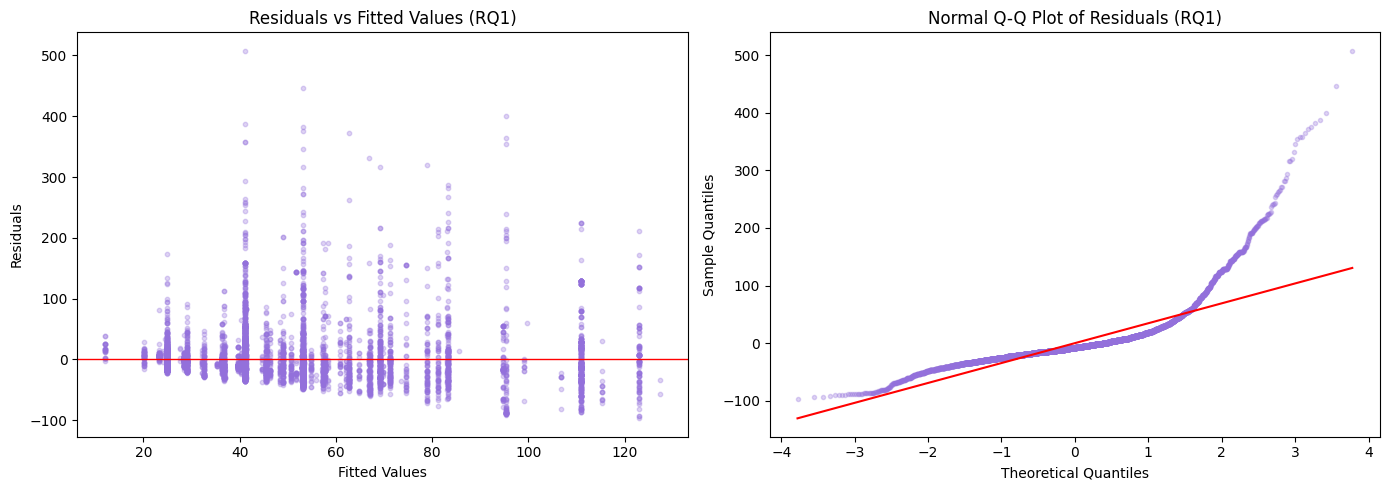

Residual plots saved.


In [ ]:
# Get fitted values and residuals
fitted_vals = model_rq1.fittedvalues
residuals = model_rq1.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
axes[0].scatter(fitted_vals, residuals, alpha=0.3, color='mediumpurple', s=10)
axes[0].axhline(0, color='red', linewidth=1)
axes[0].set_title("Residuals vs Fitted Values (RQ1)")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

# QQ Plot
import scipy.stats as stats
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist="norm")
axes[1].plot(osm, osr, 'o', alpha=0.3, color='mediumpurple', markersize=3)
axes[1].plot(osm, slope*np.array(osm)+intercept, 'r-')
axes[1].set_title("Normal Q-Q Plot of Residuals (RQ1)")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")

plt.tight_layout()
plt.savefig("rq1_residuals.png", dpi=150, bbox_inches='tight')
plt.show()
print("Residual plots saved.")

####**R² and MSE**

In [ ]:
# Train-test split for prediction accuracy
X_train, X_test, y_train, y_test = train_test_split(
    X_rq1, y_rq1, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared (test set): {r2:.4f}")
print(f"MSE (test set): {mse:.4f}")
print(f"RMSE (test set): {rmse:.4f}")

R-squared (test set): 0.2396
MSE (test set): 1716.2287
RMSE (test set): 41.4274


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.269
Model:                            OLS   Adj. R-squared:                  0.268
Method:                 Least Squares   F-statistic:                     248.0
Date:                Sun, 26 Apr 2026   Prob (F-statistic):               0.00
Time:                        03:59:12   Log-Likelihood:                -8366.6
No. Observations:                8770   AIC:                         1.676e+04
Df Residuals:                    8756   BIC:                         1.686e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

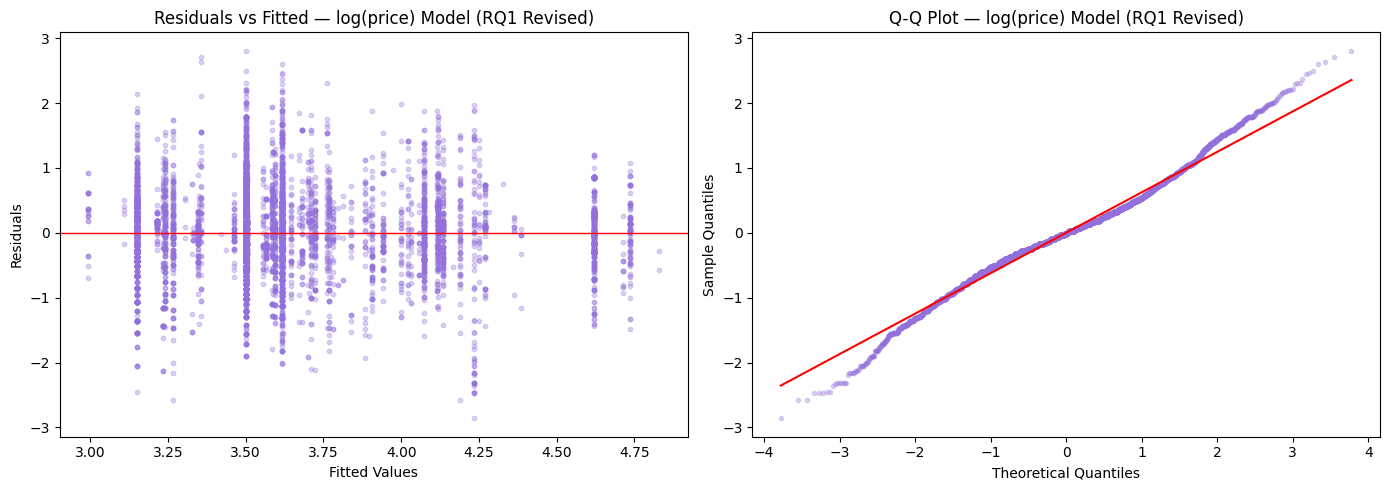

In [ ]:
#Revised Model with log(price)
y_rq1_log = np.log(y_rq1)
X_rq1_const_log = sm.add_constant(X_rq1.astype(float))

model_rq1_log = sm.OLS(y_rq1_log, X_rq1_const_log).fit()
print(model_rq1_log.summary())

# Revised residual plots
fitted_log = model_rq1_log.fittedvalues
resid_log = model_rq1_log.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(fitted_log, resid_log, alpha=0.3, color='mediumpurple', s=10)
axes[0].axhline(0, color='red', linewidth=1)
axes[0].set_title("Residuals vs Fitted — log(price) Model (RQ1 Revised)")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

(osm, osr), (slope, intercept, r) = stats.probplot(resid_log, dist="norm")
axes[1].plot(osm, osr, 'o', alpha=0.3, color='mediumpurple', markersize=3)
axes[1].plot(osm, slope*np.array(osm)+intercept, 'r-')
axes[1].set_title("Q-Q Plot — log(price) Model (RQ1 Revised)")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")

plt.tight_layout()
plt.savefig("rq1_revised_residuals.png", dpi=150, bbox_inches='tight')
plt.show()

###**Question - 2**
####**Data Prep for Logistic Regression**

In [ ]:
# Create binary response variable
df_clean['high_rating'] = (df_clean['rating'] >= 4.0).astype(int)

# Use same category grouping from RQ1
df_rq2 = pd.get_dummies(df_clean[['high_rating', 'price', 'number_of_reviews',
                                    'love', 'category_grouped']],
                          columns=['category_grouped'], drop_first=True)

df_rq2 = df_rq2.astype({col: int for col in df_rq2.select_dtypes(include='bool').columns})

print("RQ2 dataset shape:", df_rq2.shape)
print("Class distribution:\n", df_rq2['high_rating'].value_counts())
print("Class proportions:\n", df_rq2['high_rating'].value_counts(normalize=True).round(3))

RQ2 dataset shape: (8770, 14)
Class distribution:
 high_rating
1    7252
0    1518
Name: count, dtype: int64
Class proportions:
 high_rating
1    0.827
0    0.173
Name: proportion, dtype: float64


####**Fit Logistic Regression (statsmodels for p-values)**

In [ ]:
X_rq2 = df_rq2.drop(columns=['high_rating']).astype(float)
y_rq2 = df_rq2['high_rating'].astype(float)

X_rq2_const = sm.add_constant(X_rq2)

logit_model = sm.Logit(y_rq2, X_rq2_const).fit()
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.440628
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            high_rating   No. Observations:                 8770
Model:                          Logit   Df Residuals:                     8756
Method:                           MLE   Df Model:                           13
Date:                Sun, 26 Apr 2026   Pseudo R-squ.:                 0.04368
Time:                        03:59:17   Log-Likelihood:                -3864.3
converged:                       True   LL-Null:                       -4040.8
Covariance Type:            nonrobust   LLR p-value:                 1.830e-67
                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
const                                       

####**Train/Test Split + Confusion Matrix + Accuracy**

Accuracy: 0.8267

Classification Report:
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00       304
         1.0       0.83      1.00      0.91      1450

    accuracy                           0.83      1754
   macro avg       0.41      0.50      0.45      1754
weighted avg       0.68      0.83      0.75      1754



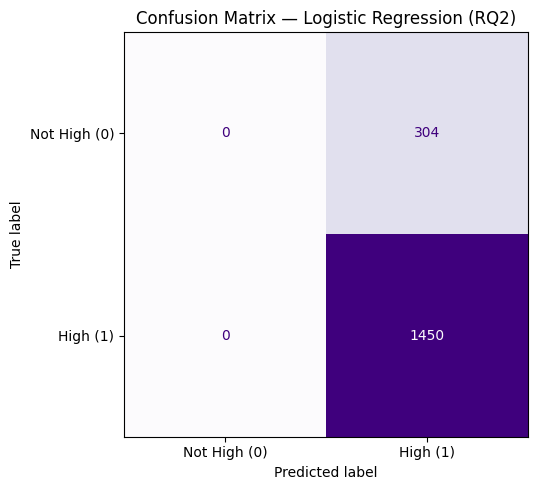

Confusion matrix saved.


In [ ]:
from sklearn.model_selection import train_test_split

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_rq2, y_rq2, test_size=0.2, random_state=42, stratify=y_rq2)

lr2 = LogisticRegression(max_iter=1000)
lr2.fit(X_train2, y_train2)
y_pred2 = lr2.predict(X_test2)

# Accuracy
acc = accuracy_score(y_test2, y_pred2)
print(f"Accuracy: {acc:.4f}")

# Classification report (precision, recall, F1)
print("\nClassification Report:")
print(classification_report(y_test2, y_pred2))

# Confusion Matrix
cm = confusion_matrix(y_test2, y_pred2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not High (0)', 'High (1)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title("Confusion Matrix — Logistic Regression (RQ2)")
plt.tight_layout()
plt.savefig("rq2_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix saved.")

####**Model Revision**

Balanced Model Accuracy: 0.5131

Classification Report (Balanced):
              precision    recall  f1-score   support

         0.0       0.23      0.77      0.35       304
         1.0       0.90      0.46      0.61      1450

    accuracy                           0.51      1754
   macro avg       0.57      0.61      0.48      1754
weighted avg       0.79      0.51      0.57      1754



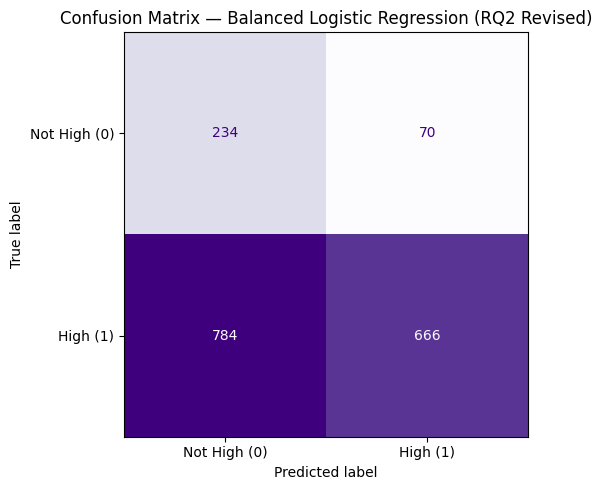

In [ ]:
# Block 17: RQ2 Revised — class_weight='balanced'
lr2_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
lr2_balanced.fit(X_train2, y_train2)
y_pred2_bal = lr2_balanced.predict(X_test2)

acc_bal = accuracy_score(y_test2, y_pred2_bal)
print(f"Balanced Model Accuracy: {acc_bal:.4f}")
print("\nClassification Report (Balanced):")
print(classification_report(y_test2, y_pred2_bal))

# Revised confusion matrix
cm_bal = confusion_matrix(y_test2, y_pred2_bal)
disp_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal,
                                   display_labels=['Not High (0)', 'High (1)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp_bal.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title("Confusion Matrix — Balanced Logistic Regression (RQ2 Revised)")
plt.tight_layout()
plt.savefig("rq2_confusion_matrix_balanced.png", dpi=150, bbox_inches='tight')
plt.show()

###**Question - 3**
####**Data Prep + Assumption Check (Normality)**

In [ ]:
from scipy import stats
import scipy.stats as stats

# Create groups
df_clean['group'] = df_clean.apply(
    lambda x: 'Exclusive' if x['exclusive'] == 1
    else ('Limited Edition' if x['limited_edition'] == 1 else 'Regular'), axis=1)

# Raw love count per group
exclusive_love = df_clean[df_clean['group'] == 'Exclusive']['love']
limited_love = df_clean[df_clean['group'] == 'Limited Edition']['love']
regular_love = df_clean[df_clean['group'] == 'Regular']['love']

print("Group sizes:")
print(df_clean['group'].value_counts())

print("\nRaw love count summary per group:")
print(df_clean.groupby('group')['love'].describe().round(2))

# Normality check on raw love (Shapiro on sample of 500 - Shapiro limited to 5000)
sample_exc = exclusive_love.sample(500, random_state=42)
sample_lim = limited_love.sample(min(500, len(limited_love)), random_state=42)
sample_reg = regular_love.sample(500, random_state=42)

stat_e, p_e = stats.shapiro(sample_exc)
stat_l, p_l = stats.shapiro(sample_lim)
stat_r, p_r = stats.shapiro(sample_reg)

print(f"\nShapiro-Wilk Test (raw love):")
print(f"Exclusive:      W={stat_e:.4f}, p={p_e:.6f}")
print(f"Limited Edition: W={stat_l:.4f}, p={p_l:.6f}")
print(f"Regular:        W={stat_r:.4f}, p={p_r:.6f}")

Group sizes:
group
Regular            6111
Exclusive          2321
Limited Edition     338
Name: count, dtype: int64

Raw love count summary per group:
                  count      mean       std   min     25%     50%      75%  \
group                                                                        
Exclusive        2321.0  20757.29  52126.96   0.0  2500.0  6900.0  19200.0   
Limited Edition   338.0   8216.56  20296.23  60.0  1225.0  2700.0   7000.0   
Regular          6111.0  16036.19  40514.02   0.0  1800.0  4900.0  13600.0   

                       max  
group                       
Exclusive        1300000.0  
Limited Edition   212200.0  
Regular           770700.0  

Shapiro-Wilk Test (raw love):
Exclusive:      W=0.5236, p=0.000000
Limited Edition: W=0.3512, p=0.000000
Regular:        W=0.4191, p=0.000000


####**Log Transform + Normality Recheck**

In [ ]:
# Apply log(1 + love) to handle zeros
df_clean['love_log'] = np.log1p(df_clean['love'])

exclusive_log = df_clean[df_clean['group'] == 'Exclusive']['love_log']
limited_log = df_clean[df_clean['group'] == 'Limited Edition']['love_log']
regular_log = df_clean[df_clean['group'] == 'Regular']['love_log']

print("Log love count summary per group:")
print(df_clean.groupby('group')['love_log'].describe().round(4))

# Normality check on log love
sample_exc_log = exclusive_log.sample(500, random_state=42)
sample_lim_log = limited_log.sample(min(500, len(limited_log)), random_state=42)
sample_reg_log = regular_log.sample(500, random_state=42)

stat_el, p_el = stats.shapiro(sample_exc_log)
stat_ll, p_ll = stats.shapiro(sample_lim_log)
stat_rl, p_rl = stats.shapiro(sample_reg_log)

print(f"\nShapiro-Wilk Test (log love):")
print(f"Exclusive:       W={stat_el:.4f}, p={p_el:.6f}")
print(f"Limited Edition: W={stat_ll:.4f}, p={p_ll:.6f}")
print(f"Regular:         W={stat_rl:.4f}, p={p_rl:.6f}")

Log love count summary per group:
                  count    mean     std     min     25%     50%     75%  \
group                                                                     
Exclusive        2321.0  8.6831  1.9957  0.0000  7.8244  8.8394  9.8627   
Limited Edition   338.0  8.0260  1.3054  4.1109  7.1109  7.9014  8.8538   
Regular          6111.0  8.4327  1.8061  0.0000  7.4961  8.4972  9.5179   

                     max  
group                     
Exclusive        14.0779  
Limited Edition  12.2653  
Regular          13.5551  

Shapiro-Wilk Test (log love):
Exclusive:       W=0.8426, p=0.000000
Limited Edition: W=0.9868, p=0.003536
Regular:         W=0.8796, p=0.000000


####**Distribution Plots (Raw vs Log)**

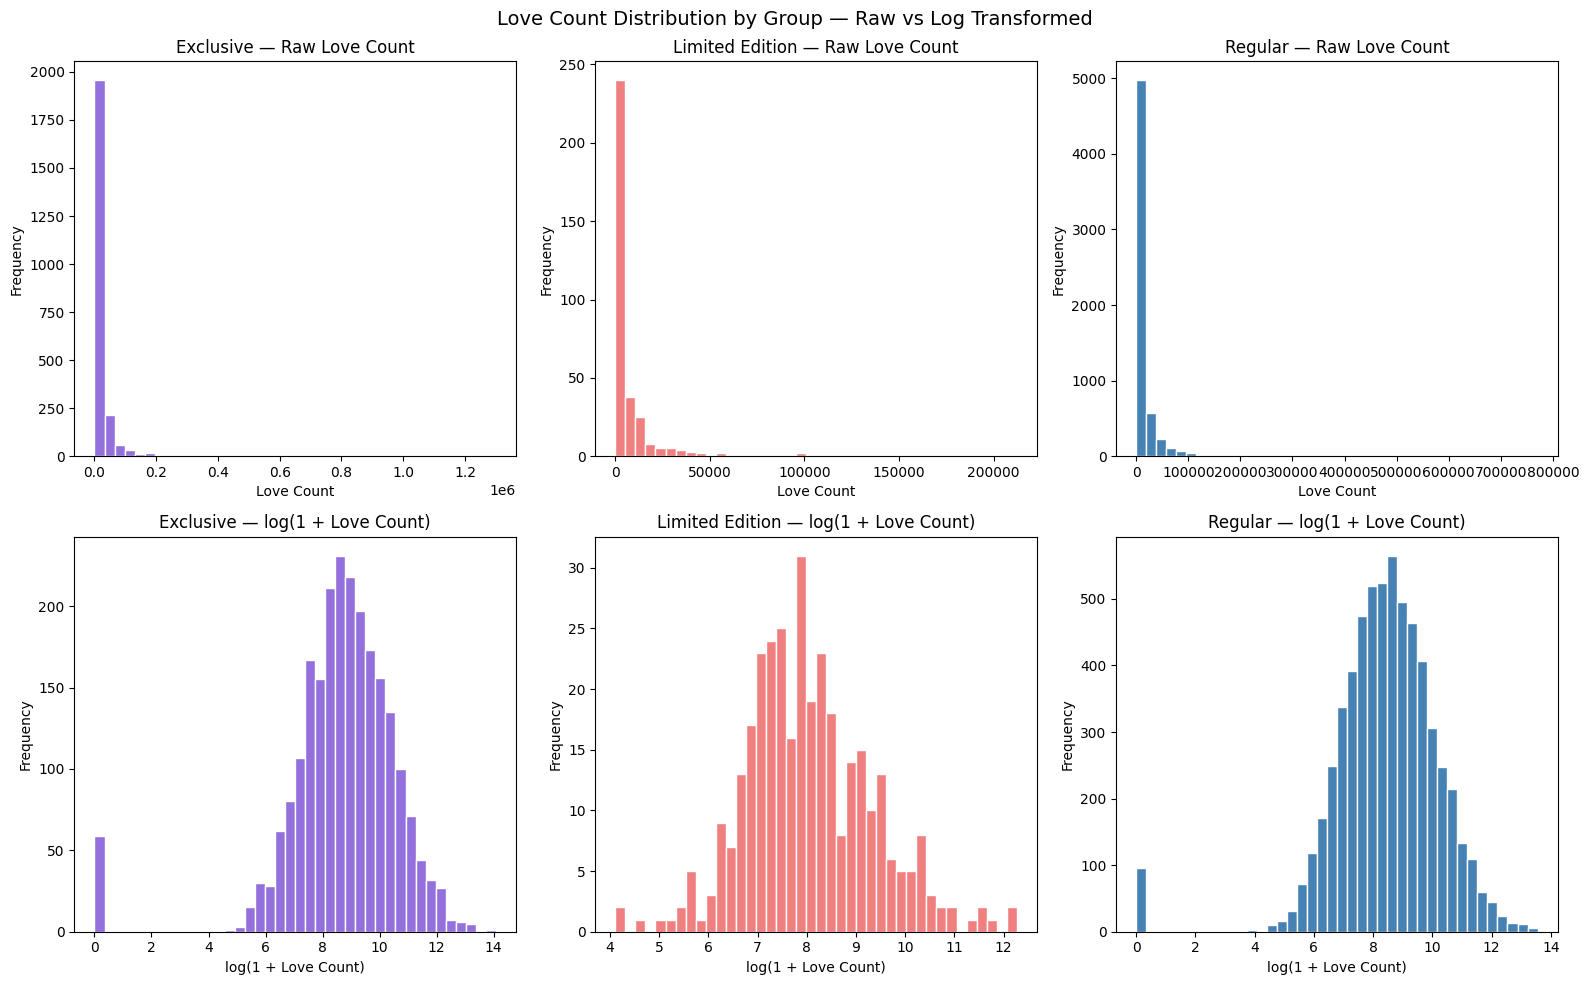

Distribution plots saved.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Love Count Distribution by Group — Raw vs Log Transformed", fontsize=14)

groups = ['Exclusive', 'Limited Edition', 'Regular']
colors = ['mediumpurple', 'lightcoral', 'steelblue']
raw_data = [exclusive_love, limited_love, regular_love]
log_data = [exclusive_log, limited_log, regular_log]

for i, (grp, col, raw, log) in enumerate(zip(groups, colors, raw_data, log_data)):
    axes[0, i].hist(raw, bins=40, color=col, edgecolor='white')
    axes[0, i].set_title(f"{grp} — Raw Love Count")
    axes[0, i].set_xlabel("Love Count")
    axes[0, i].set_ylabel("Frequency")

    axes[1, i].hist(log, bins=40, color=col, edgecolor='white')
    axes[1, i].set_title(f"{grp} — log(1 + Love Count)")
    axes[1, i].set_xlabel("log(1 + Love Count)")
    axes[1, i].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("rq3_distributions.png", dpi=150, bbox_inches='tight')
plt.show()
print("Distribution plots saved.")

####**t-test (Exclusive vs Regular)**

In [ ]:
# Independent samples t-test: Exclusive vs Regular (on log love)
t_stat, p_val_t = stats.ttest_ind(exclusive_log, regular_log, equal_var=False)

print("Independent Samples t-test (Welch's): Exclusive vs Regular")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_val_t:.6f}")

if p_val_t < 0.05:
    print("Result: Reject H0 — significant difference in mean log love count")
else:
    print("Result: Fail to reject H0 — no significant difference")

print(f"\nMean log love — Exclusive: {exclusive_log.mean():.4f}")
print(f"Mean log love — Regular:   {regular_log.mean():.4f}")

Independent Samples t-test (Welch's): Exclusive vs Regular
t-statistic: 5.2796
p-value:     0.000000
Result: Reject H0 — significant difference in mean log love count

Mean log love — Exclusive: 8.6831
Mean log love — Regular:   8.4327


####**One-Way ANOVA (All Three Groups)**

In [ ]:
# One-way ANOVA across all three groups
f_stat, p_val_anova = stats.f_oneway(exclusive_log, limited_log, regular_log)

print("One-Way ANOVA: Exclusive vs Limited Edition vs Regular")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_val_anova:.6f}")

if p_val_anova < 0.05:
    print("Result: Reject H0 — at least one group mean is significantly different")
else:
    print("Result: Fail to reject H0 — no significant difference between groups")

One-Way ANOVA: Exclusive vs Limited Edition vs Regular
F-statistic: 26.3801
p-value:     0.000000
Result: Reject H0 — at least one group mean is significantly different


####**Post-hoc Tukey HSD Test**

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Combine log love and group labels
love_all = np.concatenate([exclusive_log, limited_log, regular_log])
groups_all = (['Exclusive'] * len(exclusive_log) +
              ['Limited Edition'] * len(limited_log) +
              ['Regular'] * len(regular_log))

tukey = pairwise_tukeyhsd(endog=love_all, groups=groups_all, alpha=0.05)
print(tukey)

         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
      Exclusive Limited Edition  -0.6571    0.0 -0.9085 -0.4058   True
      Exclusive         Regular  -0.2504    0.0 -0.3557 -0.1451   True
Limited Edition         Regular   0.4067 0.0002  0.1654   0.648   True
----------------------------------------------------------------------


####**Kruskal-Wallis Test (Non-parametric check)**

In [ ]:
# Kruskal-Wallis as non-parametric alternative (since normality may still be violated)
kw_stat, kw_p = stats.kruskal(exclusive_log, limited_log, regular_log)

print("Kruskal-Wallis Test (non-parametric alternative to ANOVA):")
print(f"H-statistic: {kw_stat:.4f}")
print(f"p-value:     {kw_p:.6f}")

if kw_p < 0.05:
    print("Result: Reject H0 — at least one group differs significantly")
else:
    print("Result: Fail to reject H0")

Kruskal-Wallis Test (non-parametric alternative to ANOVA):
H-statistic: 128.5741
p-value:     0.000000
Result: Reject H0 — at least one group differs significantly


##**7. RESULTS**

###**Question - 1**
####**Coefficient Plot**

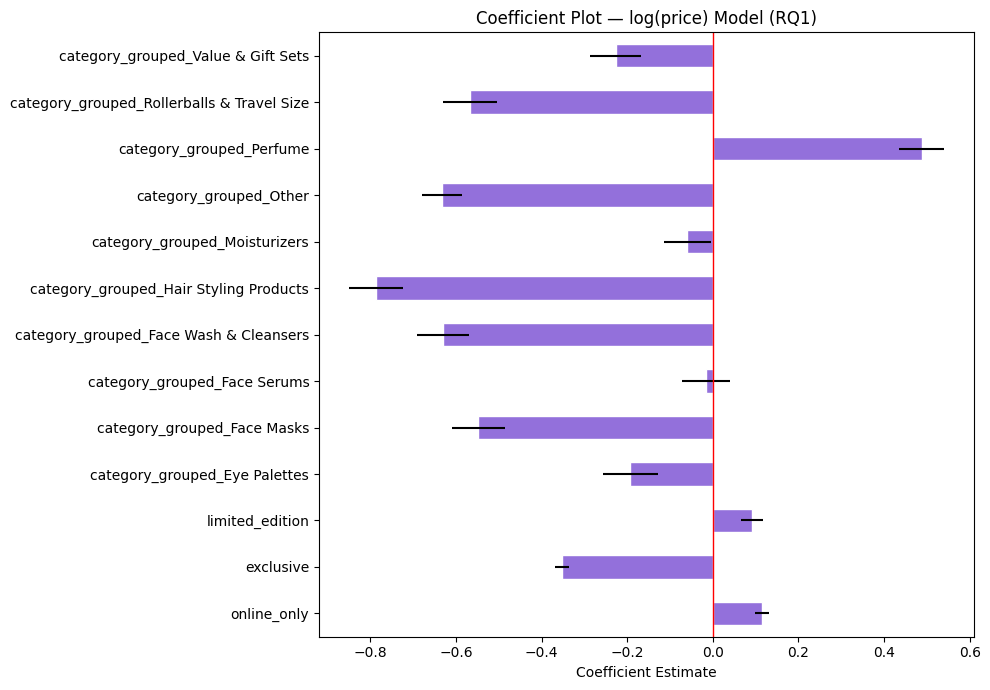

In [ ]:
# Coefficient plot for revised model (excluding const)
coefs = model_rq1_log.params[1:]
errors = model_rq1_log.bse[1:]

fig, ax = plt.subplots(figsize=(10, 7))
coefs.plot(kind='barh', xerr=errors, ax=ax, color='mediumpurple', edgecolor='white')
ax.axvline(0, color='red', linewidth=1)
ax.set_title("Coefficient Plot — log(price) Model (RQ1)")
ax.set_xlabel("Coefficient Estimate")
plt.tight_layout()
plt.savefig("rq1_coefficients.png", dpi=150, bbox_inches='tight')
plt.show()

####**Actual vs Predicted**

R-squared (log scale, test set): 0.2714
RMSE (original price scale, test set): $43.12


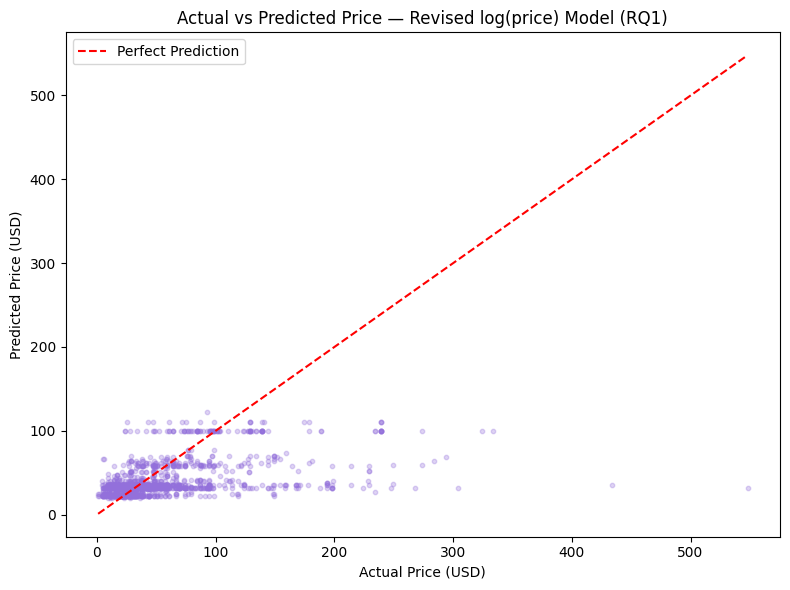

Actual vs predicted plot saved.


In [ ]:
# Actual vs Predicted for log(price) revised model
X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_rq1.astype(float), y_rq1_log.astype(float),
    test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

lr1 = LinearRegression()
lr1.fit(X_train1, y_train1)
y_pred1_log = lr1.predict(X_test1)

# Convert back to original price scale
y_pred1_price = np.expm1(y_pred1_log)
y_test1_price = np.expm1(y_test1)

r2_log = r2_score(y_test1, y_pred1_log)
rmse_price = np.sqrt(mean_squared_error(y_test1_price, y_pred1_price))

print(f"R-squared (log scale, test set): {r2_log:.4f}")
print(f"RMSE (original price scale, test set): ${rmse_price:.2f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test1_price, y_pred1_price, alpha=0.3, color='mediumpurple', s=10)
ax.plot([y_test1_price.min(), y_test1_price.max()],
        [y_test1_price.min(), y_test1_price.max()],
        'r--', linewidth=1.5, label='Perfect Prediction')
ax.set_title("Actual vs Predicted Price — Revised log(price) Model (RQ1)")
ax.set_xlabel("Actual Price (USD)")
ax.set_ylabel("Predicted Price (USD)")
ax.legend()
plt.tight_layout()
plt.savefig("rq1_actual_vs_predicted.png", dpi=150, bbox_inches='tight')
plt.show()
print("Actual vs predicted plot saved.")

###**Question - 2**
####**Coefficient Plot**

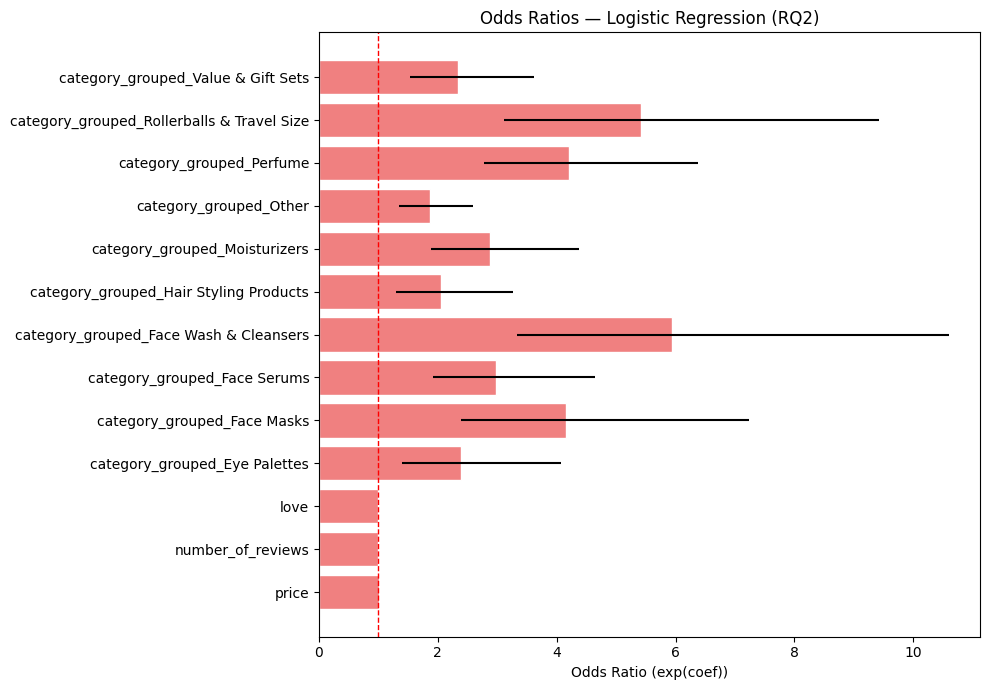

Odds ratio plot saved.


In [ ]:
# Odds ratios from statsmodels model
odds_ratios = np.exp(logit_model.params[1:])  # exclude const
conf_int = np.exp(logit_model.conf_int().iloc[1:])  # exclude const

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(odds_ratios.index, odds_ratios.values,
        xerr=[odds_ratios.values - conf_int[0].values,
              conf_int[1].values - odds_ratios.values],
        color='lightcoral', edgecolor='white')
ax.axvline(1, color='red', linewidth=1, linestyle='--')
ax.set_title("Odds Ratios — Logistic Regression (RQ2)")
ax.set_xlabel("Odds Ratio (exp(coef))")
plt.tight_layout()
plt.savefig("rq2_odds_ratios.png", dpi=150, bbox_inches='tight')
plt.show()
print("Odds ratio plot saved.")

####**ROC Curve**

AUC Score (Balanced Model): 0.6641


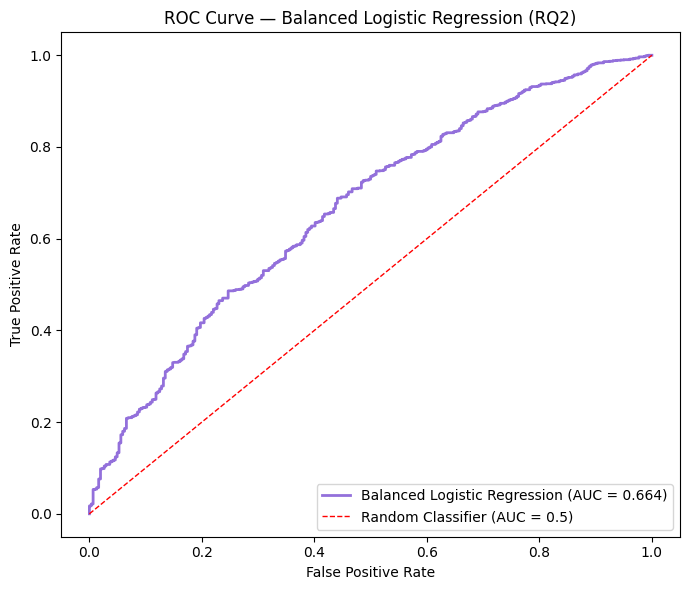

ROC curve saved.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities from balanced model
y_prob_bal = lr2_balanced.predict_proba(X_test2)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test2, y_prob_bal)
auc_score = roc_auc_score(y_test2, y_prob_bal)

print(f"AUC Score (Balanced Model): {auc_score:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='mediumpurple', linewidth=2,
        label=f'Balanced Logistic Regression (AUC = {auc_score:.3f})')
ax.plot([0, 1], [0, 1], 'r--', linewidth=1, label='Random Classifier (AUC = 0.5)')
ax.set_title("ROC Curve — Balanced Logistic Regression (RQ2)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig("rq2_roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()
print("ROC curve saved.")

###**Question - 3**
####**Visualization for Results**

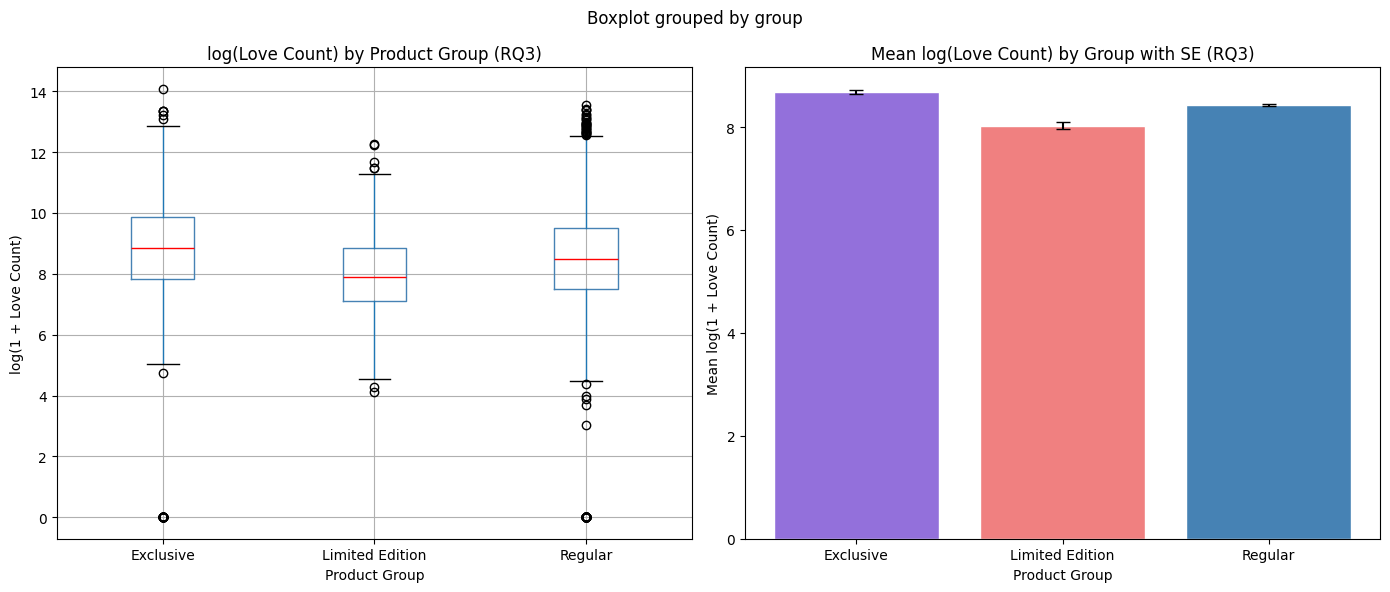

RQ3 result plots saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot of log love by group
df_clean.boxplot(column='love_log', by='group', ax=axes[0],
                 boxprops=dict(color='steelblue'),
                 medianprops=dict(color='red'))
axes[0].set_title("log(Love Count) by Product Group")
axes[0].set_xlabel("Product Group")
axes[0].set_ylabel("log(1 + Love Count)")
plt.sca(axes[0])
plt.title("log(Love Count) by Product Group (RQ3)")

# Mean love count bar chart with error bars
group_stats = df_clean.groupby('group')['love_log'].agg(['mean', 'std', 'count'])
group_stats['se'] = group_stats['std'] / np.sqrt(group_stats['count'])

axes[1].bar(group_stats.index, group_stats['mean'],
            yerr=group_stats['se'], color=['mediumpurple', 'lightcoral', 'steelblue'],
            edgecolor='white', capsize=5)
axes[1].set_title("Mean log(Love Count) by Group with SE (RQ3)")
axes[1].set_xlabel("Product Group")
axes[1].set_ylabel("Mean log(1 + Love Count)")

plt.tight_layout()
plt.savefig("rq3_results.png", dpi=150, bbox_inches='tight')
plt.show()
print("RQ3 result plots saved.")

###**10. Appendix**

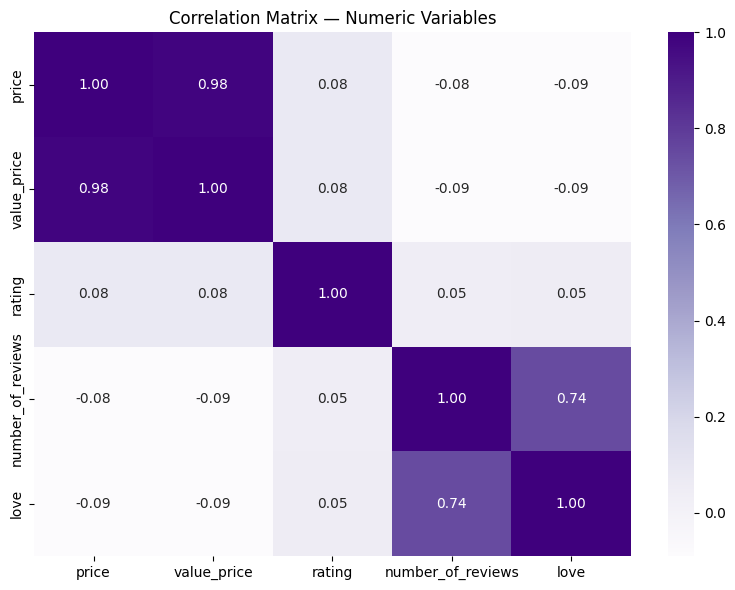

In [ ]:
numeric_cols = df_clean[['price', 'value_price', 'rating',
                          'number_of_reviews', 'love']].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_cols, annot=True, fmt='.2f',
            cmap='Purples', ax=ax)
ax.set_title("Correlation Matrix — Numeric Variables")
plt.tight_layout()
plt.savefig("appendix_correlation.png", dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(df_clean['category'].value_counts().to_string())

category
Perfume                            656
Moisturizers                       442
Face Serums                        378
Value & Gift Sets                  316
Face Wash & Cleansers              245
Face Masks                         226
Rollerballs & Travel Size          220
Hair Styling Products              213
Eye Palettes                       199
Eye Creams & Treatments            189
Lipstick                           188
Face Brushes                       176
Shampoo                            176
Foundation                         163
Highlighter                        161
Cologne                            154
Mascara                            153
Face Primer                        143
Mini Size                          141
Conditioner                        139
Candles & Home Scents              127
Eyeliner                           123
Setting Spray & Powder             115
Makeup                             108
Body Lotions & Body Oils           108
Beauty Supplemen

In [ ]:
print(df_clean['brand'].value_counts().to_string())

brand
SEPHORA COLLECTION                  465
CLINIQUE                            219
tarte                               169
TOM FORD                            154
Fresh                               137
Dior                                137
Kiehl's Since 1851                  124
Lancôme                             114
Bumble and bumble                   101
MAKE UP FOR EVER                     98
Shiseido                             92
Benefit Cosmetics                    90
Kérastase                            89
Moroccanoil                          88
FENTY BEAUTY by Rihanna              81
philosophy                           79
Too Faced                            78
Bobbi Brown                          74
Urban Decay                          74
Origins                              73
Jo Malone London                     73
Charlotte Tilbury                    73
Givenchy                             72
Yves Saint Laurent                   71
KVD Vegan Beauty                  